# CoKriging Multi-Fidelity Spot Check (2D)

Single fit of `SurrogateModels.cokriging.CoKriging` on the 2D test function (`PeaksShifted2`). This is the Kriging counterpart of `CompositeNN_2DSpotCheck.ipynb`, and it uses the same LF, HF, and test samples, so the test RMSEs compare directly.

`CoKriging` fits in two stages:
1. **LF fit:** a `Kriging` model is fit to the LF samples.
2. **MF fit:** a `DiffKriging` model is fit to `y_hf - rho * y_lf(x)` at the HF samples, with `rho` optimized alongside its other hyperparameters. The two models are then combined in a block covariance matrix.

As a baseline, an **HF-only fit** trains a separate `Kriging` model on just the HF samples, with the same nugget. Comparing it with the MF fit shows how much the LF data helps.

With `scale_input=True`, `x` is scaled to [-1, 1] using the function's bounds. Neither model scales its outputs, so all errors here are in original units. Unlike the NN fits, these fits have no random initialization, so rerunning gives the same result.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from SurrogateModels import cokriging, kriging

### Data

In [2]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()

n_lf = 400
n_hf = 100
seed = 0

X_lf = my_function.sample_random(n_lf, seed=seed)
y_lf = my_function.low_fidelity(X_lf)
X_hf = my_function.sample_random(n_hf, seed=seed)
y_hf = my_function.high_fidelity(X_hf)

# Shared test locations, evaluated with each fidelity
X_test = my_function.sample_random(1000, seed=1234)
y_lf_test = my_function.low_fidelity(X_test)
y_hf_test = my_function.high_fidelity(X_test)

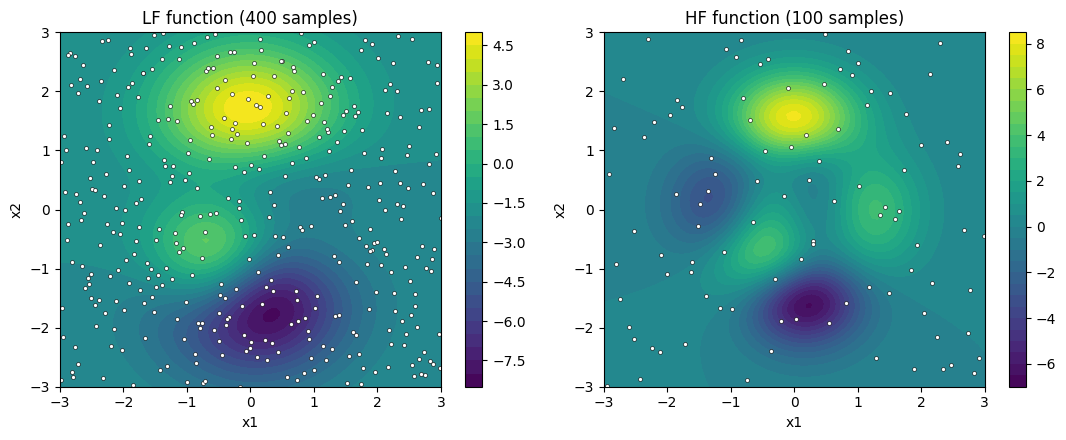

In [3]:
# Contour grid over the function's bounds, reused for all plots below
n_grid = 100
(x1_min, x1_max), (x2_min, x2_max) = my_function.bounds
X1, X2 = np.meshgrid(np.linspace(x1_min, x1_max, n_grid), np.linspace(x2_min, x2_max, n_grid))
X_grid = np.column_stack([X1.ravel(), X2.ravel()])
y_lf_grid = my_function.low_fidelity(X_grid).reshape(n_grid, n_grid)
y_hf_grid = my_function.high_fidelity(X_grid).reshape(n_grid, n_grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, Z, X_s, title in [
    (axes[0], y_lf_grid, X_lf, f"LF function ({n_lf} samples)"),
    (axes[1], y_hf_grid, X_hf, f"HF function ({n_hf} samples)"),
]:
    cs = ax.contourf(X1, X2, Z, levels=30, cmap="viridis")
    ax.scatter(X_s[:, 0], X_s[:, 1], s=8, color="white", edgecolor="black", linewidth=0.4)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    fig.colorbar(cs, ax=ax)
plt.tight_layout()
plt.show()

### Train

In [4]:
settings = dict(
    nugget=1e-3,
    scale_input=True,
    bounds=my_function.bounds,
)

ck_model = cokriging.CoKriging(X_lf, y_lf, X_hf, y_hf, **settings)

# The internal LF model was fit on scaled x and doesn't scale its own inputs,
# so it has to be given scaled x
lf_kriging = ck_model.kriging_lf
diff_kriging = ck_model.kriging_diff
lf_error = float(lf_kriging.model_error(ck_model.x_scale.transform(X_test), y_lf_test))
mf_error = float(ck_model.model_error(X_test, y_hf_test))
print(f"Train time: {ck_model.training_time:.1f}s")
print(f"LF fit test RMSE (vs LF function): {lf_error:.4g}")
print(f"MF fit test RMSE (vs HF function): {mf_error:.4g}")

Train time: 33.6s
LF fit test RMSE (vs LF function): 0.003138
MF fit test RMSE (vs HF function): 0.1751


In [5]:
# HF-only baseline: same nugget and scaling, fit on the HF samples alone
hf_kriging = kriging.Kriging(X_hf, y_hf, **settings)

hf_error = float(hf_kriging.model_error(X_test, y_hf_test))
print(f"Train time: {hf_kriging.training_time:.1f}s")
print(f"HF-only fit test RMSE (vs HF function): {hf_error:.4g}")
print(f"MF fit test RMSE (vs HF function):      {mf_error:.4g}")

Train time: 5.4s
HF-only fit test RMSE (vs HF function): 0.1255
MF fit test RMSE (vs HF function):      0.1751


### Hyperparameters

Kriging has no training history, so this replaces the convergence plots of the NN notebook. `theta` is per input, on scaled `x`, and larger values mean the function varies faster along that input. The optimizer limits `theta` to [1e-3, 1e3], so a value at either limit means the fit is constrained. `sigma2` is the process variance, and `rho` scales the LF model in the MF fit.

In [6]:
for name, fit in [("LF", lf_kriging), ("Difference", diff_kriging), ("HF-only", hf_kriging)]:
    print(
        f"{name}: theta {np.round(fit.theta, 3)}, p {np.round(fit.p, 3)}, "
        f"sigma2 {fit.sigma.item():.4g}"
    )
print(f"rho: {diff_kriging.scale_factor:.4g}")

LF: theta [6.121 7.265], p [2. 2.], sigma2 0.3381
Difference: theta [10.459 11.786], p [2. 2.], sigma2 1.067
HF-only: theta [ 8.694 10.392], p [2. 2.], sigma2 2.369
rho: 0.8236


### Fit quality

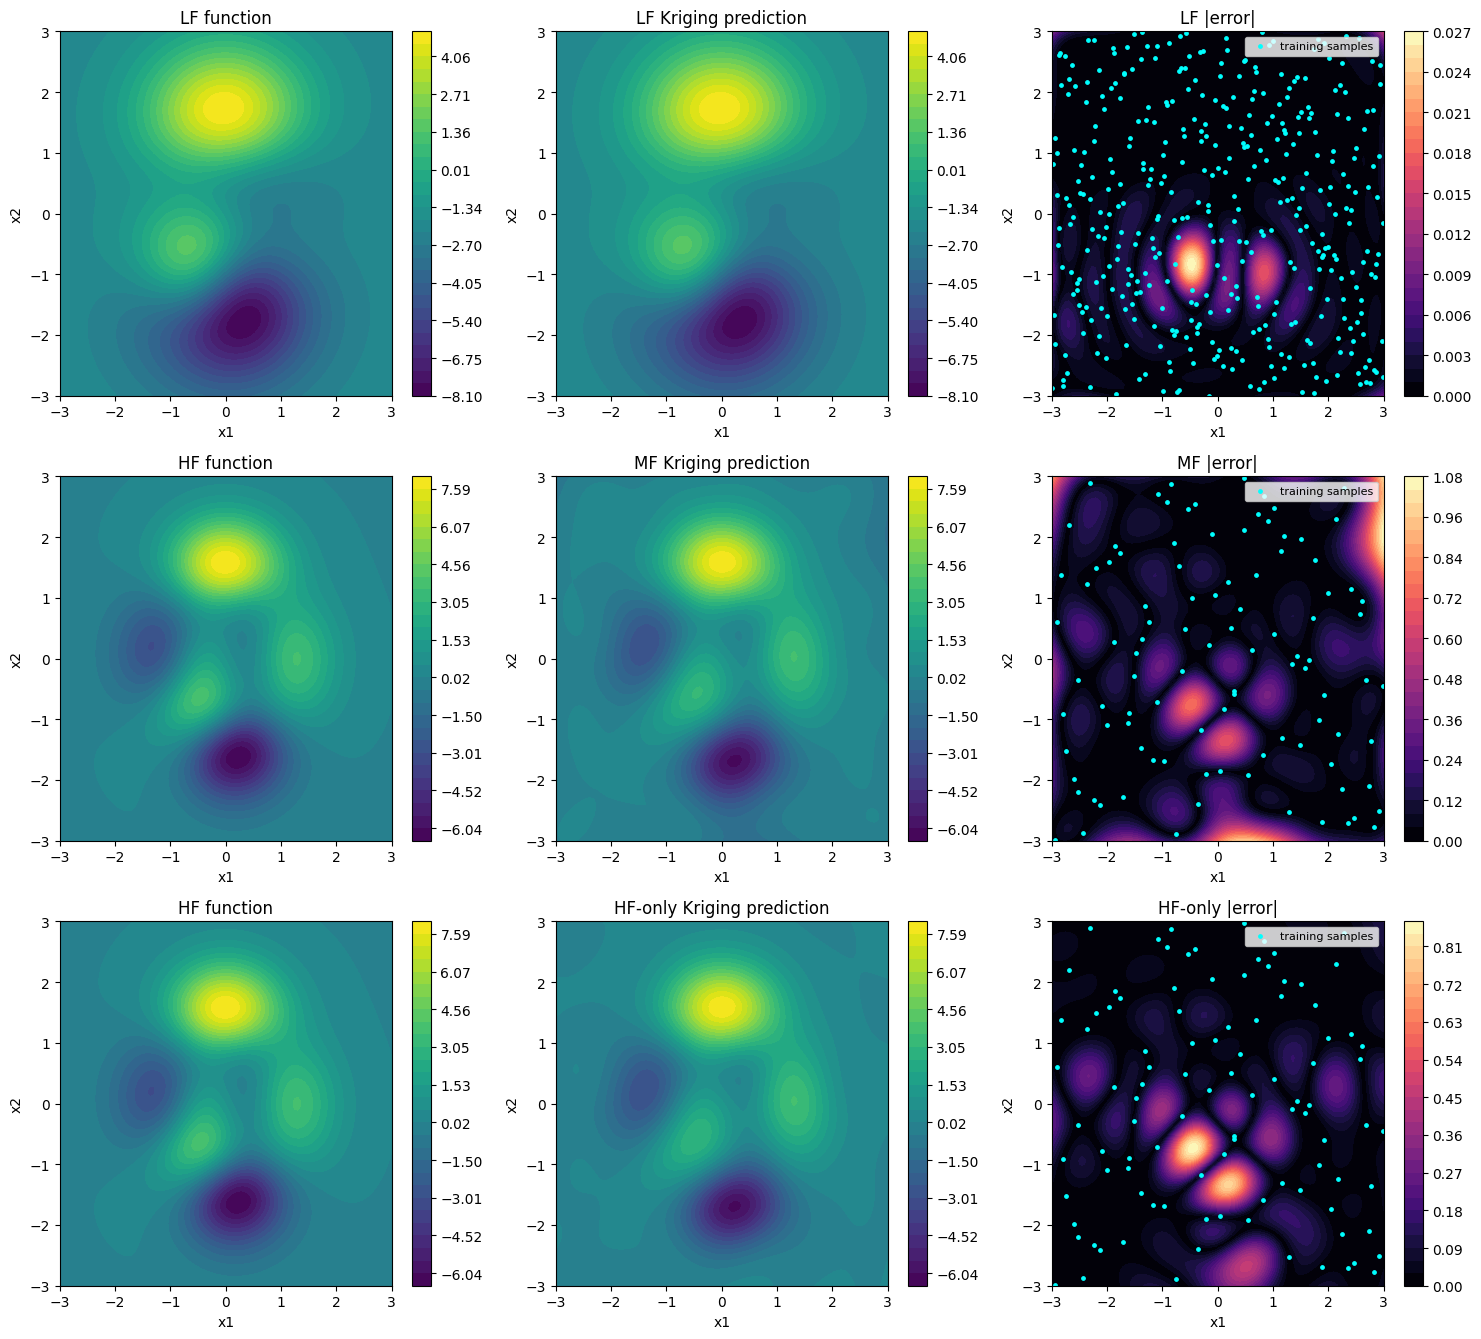

In [7]:
y_lf_hat_grid = lf_kriging.evaluate(ck_model.x_scale.transform(X_grid)).reshape(n_grid, n_grid)
y_mf_hat_grid = ck_model.evaluate(X_grid).reshape(n_grid, n_grid)
y_hf_hat_grid = hf_kriging.evaluate(X_grid).reshape(n_grid, n_grid)

rows = [
    ("LF", y_lf_grid, y_lf_hat_grid, X_lf),
    ("MF", y_hf_grid, y_mf_hat_grid, X_hf),
    ("HF-only", y_hf_grid, y_hf_hat_grid, X_hf),
]
fig, axes = plt.subplots(3, 3, figsize=(15, 13.5))
for row, (name, Z_true, Z_hat, X_s) in zip(axes, rows):
    levels = np.linspace(min(Z_true.min(), Z_hat.min()), max(Z_true.max(), Z_hat.max()), 30)
    target = "LF" if name == "LF" else "HF"
    for ax, Z, title in [
        (row[0], Z_true, f"{target} function"),
        (row[1], Z_hat, f"{name} Kriging prediction"),
    ]:
        cs = ax.contourf(X1, X2, Z, levels=levels, cmap="viridis")
        fig.colorbar(cs, ax=ax)
        ax.set_title(title)
    cs = row[2].contourf(X1, X2, np.abs(Z_hat - Z_true), levels=30, cmap="magma")
    row[2].scatter(X_s[:, 0], X_s[:, 1], s=6, color="cyan", label="training samples")
    fig.colorbar(cs, ax=row[2])
    row[2].set_title(f"{name} |error|")
    row[2].legend(loc="upper right", fontsize=8)
    for ax in row:
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
plt.tight_layout()
plt.show()